# Aprendizaje semisupervisado: ¿cuándo ayudan los datos sin etiqueta?

**Ejemplo computacional · Exposición de Aprendizaje Automático · Universidad EAFIT, 2026-2**
Juan Alberto · Alejandro García · Daniel · Juan Esteban

---

El aprendizaje semisupervisado parte de una situación frecuente en la práctica: obtener datos es barato, pero etiquetarlos es costoso. La idea es combinar unas pocas observaciones etiquetadas con muchas sin etiquetar para entrenar un mejor clasificador. Esa promesa tiene condiciones. Los datos deben cumplir ciertos supuestos (suavidad, clústeres, variedad de baja dimensión) y algunos métodos, como el self-training, pueden reforzar sus propios errores.

En este notebook estudiamos esas condiciones con experimentos controlados y repetidos. La pregunta que guía el trabajo es:

> **Con un presupuesto fijo de etiquetas, ¿cuánto mejora un clasificador al añadir datos sin etiqueta, de qué depende esa mejora y cuándo desaparece o se vuelve negativa?**

| Parte | Contenido |
|---|---|
| 1. Intuición en 2D | Dos lunas: frontera de decisión con y sin datos sin etiqueta, y propagación de etiquetas por un grafo |
| 2. Cuándo falla | Debilitamos a propósito el supuesto de clúster aumentando el ruido |
| 3. Dígitos escritos a mano | Experimento principal con 20 repeticiones y curva de aprendizaje |
| 4. Self-training en detalle | Umbral de confianza, calidad de las pseudo-etiquetas y sesgo de confirmación |
| 5. Conclusiones | Respuesta a la pregunta, hallazgos y limitaciones |

### Decisiones metodológicas

- **Comparaciones dentro de la misma familia de modelos.** El self-training, que envuelve una regresión logística, se compara con la regresión logística; label spreading, que se basa en un grafo de vecinos, se compara con el clasificador de 1 vecino más cercano (1-NN). Así la mejora puede atribuirse a los datos sin etiqueta y no a un cambio de modelo.
- **Etiquetas balanceadas por clase.** Por ejemplo, 50 etiquetas corresponden a 5 por dígito, que es el protocolo habitual en la literatura (Oliver et al., 2018; Sohn et al., 2020).
- **Repeticiones.** Cada configuración se repite con particiones y etiquetas distintas. Reportamos la media, la dispersión y el número de repeticiones en que gana cada método.
- **El conjunto de prueba solo se usa para evaluar.** Los hiperparámetros se fijan de antemano: umbral de 0,8, 7 vecinos y α = 0,99, el valor propuesto por Zhou et al. (2004).

## 0. Configuración y reproducibilidad

Todo lo aleatorio (particiones, elección de etiquetas y datos sintéticos) se deriva de una única semilla, `RANDOM_SEED`. Los datos vienen incluidos en scikit-learn, por lo que no hay descargas ni rutas locales. Las versiones de las librerías están fijadas en `requirements.txt` y `uv.lock`; la celda siguiente las imprime como registro. Las figuras se guardan en la carpeta `figures/`.

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from matplotlib.collections import LineCollection
from scipy import stats
from sklearn.datasets import load_digits, make_moons
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import recall_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.semi_supervised import LabelSpreading, SelfTrainingClassifier

for library in (np, pd, scipy, sklearn, matplotlib):
    print(f"{library.__name__:<12} {library.__version__}")

numpy        2.5.3
pandas       3.0.6
scipy        1.18.1
sklearn      1.9.1
matplotlib   3.11.2


In [2]:
# --- Reproducibilidad -------------------------------------------------------
RANDOM_SEED = 42                     # semilla base: todo lo aleatorio deriva de ella
UNLABELED = -1                       # convención de scikit-learn para "sin etiqueta"

# --- Experimento con dígitos (partes 3 y 4) ---------------------------------
TEST_SIZE = 0.30                     # 540 de las 1.797 imágenes se reservan para prueba
N_REPETITIONS = 20                   # particiones + selecciones de etiquetas independientes
LABEL_BUDGETS = [10, 20, 50, 100, 200]   # etiquetas disponibles (balanceadas: 1, 2, 5, 10, 20 por clase)
MAIN_BUDGET = 50                     # escenario principal: 5 etiquetas por dígito
THRESHOLDS = [0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99]   # umbrales explorados en la parte 4

# --- Hiperparámetros de los métodos (fijados a priori, no ajustados) --------
CONFIDENCE_THRESHOLD = 0.8           # self-training: confianza mínima para aceptar una pseudo-etiqueta
N_NEIGHBORS = 7                      # label spreading: vecinos por nodo del grafo
ALPHA = 0.99                         # label spreading: peso de los vecinos frente a la etiqueta inicial
LS_MAX_ITER = 1000                   # iteraciones máximas de la propagación

# --- Experimento con dos lunas (partes 1 y 2) -------------------------------
MOONS_N_TRAIN = 300                  # puntos de entrenamiento
MOONS_N_TEST = 2000                  # puntos nuevos de la misma distribución para medir exactitud
MOONS_LABELS_PER_CLASS = 3           # 6 etiquetas en total
MOONS_NOISE = 0.10                   # ruido del ejemplo principal
MOONS_NOISE_LEVELS = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]
MOONS_REPETITIONS = 30

FIGURES_DIR = Path("figures")
FIGURES_DIR.mkdir(exist_ok=True)

In [3]:
# Paleta: azul y naranja para las dos clases (dos lunas) y las dos familias de métodos.
BLUE, ORANGE = "#2B7BD6", "#E8673A"
LIGHT_BLUE, LIGHT_ORANGE = "#DCE8F7", "#FBE3D9"
GRAY, LIGHT_GRAY, INK = "#6B7280", "#C9CDD3", "#1F2937"
CLASS_COLORS = np.array([BLUE, ORANGE])

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelcolor": INK,
    "axes.edgecolor": GRAY,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#E5E7EB",
    "grid.linewidth": 0.8,
    "legend.frameon": False,
    "xtick.color": GRAY,
    "ytick.color": GRAY,
})

# Estilo de cada método: el color indica la familia (naranja = regresión logística,
# azul = vecinos/grafo) y el trazo indica si usa datos sin etiqueta (continuo) o no (discontinuo).
METHODS = {
    "lr": dict(label="Supervisado · regresión logística", color=ORANGE, linestyle="--", marker="o", mfc="white"),
    "self_training": dict(label="Self-training · regresión logística", color=ORANGE, linestyle="-", marker="o", mfc=ORANGE),
    "knn1": dict(label="Supervisado · 1-NN", color=BLUE, linestyle="--", marker="s", mfc="white"),
    "label_spreading": dict(label="Label spreading · grafo 7-NN", color=BLUE, linestyle="-", marker="s", mfc=BLUE),
}
# Cada método semisupervisado frente a su contraparte supervisada de la misma familia.
PAIRS = {"self_training": "lr", "label_spreading": "knn1"}


def pct(value, decimals=1):
    # Formato de porcentaje con coma decimal.
    return f"{100 * value:.{decimals}f} %".replace(".", ",")


def save_figure(fig, name):
    # Guarda la figura en figures/ con resolución suficiente para proyectarla.
    path = FIGURES_DIR / f"{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white")
    print(f"Figura guardada en {path.as_posix()}")


def plot_mean_with_ci(ax, x, values_by_x, label, color, linestyle="-", marker="o", mfc=None):
    # Media entre repeticiones y banda con el intervalo de confianza del 95 % de esa media
    # (t de Student). values_by_x es un groupby: un grupo de repeticiones por cada valor de x.
    means = values_by_x.mean()
    half_width = values_by_x.sem() * stats.t.ppf(0.975, values_by_x.count() - 1)
    ax.plot(x, means, label=label, color=color, linestyle=linestyle, marker=marker,
            markerfacecolor=mfc or color, markersize=7, linewidth=2)
    ax.fill_between(x, means - half_width, means + half_width, color=color, alpha=0.15, linewidth=0)


def plot_method(ax, x, values_by_x, method):
    style = METHODS[method]
    plot_mean_with_ci(ax, x, values_by_x, style["label"], style["color"], style["linestyle"],
                      style["marker"], style["mfc"])

### Herramientas comunes

Trabajamos con dos métodos clásicos, ambos implementados en `sklearn.semi_supervised`:

**Self-training** (Yarowsky, 1995). Envuelve un clasificador supervisado, en nuestro caso una regresión logística. Lo entrena con las observaciones etiquetadas, predice sobre las no etiquetadas, acepta como *pseudo-etiquetas* las predicciones cuya probabilidad supera un umbral y repite el proceso hasta que no se agregan nuevas pseudo-etiquetas (o hasta 10 iteraciones).

**Label spreading** (Zhou et al., 2004). Construye un grafo en el que cada punto se une a sus vecinos más cercanos y propaga las etiquetas iterando

$$F^{(t+1)} = \alpha\, S\, F^{(t)} + (1-\alpha)\, Y, \qquad S = D^{-1/2}\, W\, D^{-1/2},$$

donde $W$ es la matriz de adyacencia del grafo, $D$ su matriz de grados, $Y$ codifica las etiquetas conocidas y $F$ las etiquetas "blandas" de todos los puntos. La iteración converge a $F^{*} = (1-\alpha)(I-\alpha S)^{-1}Y$. Un $\alpha$ cercano a 1 deja que la información viaje lejos por el grafo; un $\alpha$ pequeño la mantiene cerca de los puntos etiquetados.

**Dos decisiones de implementación**, justificadas por el funcionamiento del algoritmo y no por la exactitud en prueba:

1. **Grafo simétrico.** Con `kernel="knn"`, scikit-learn construye un grafo *dirigido* ("j es vecino de i" no implica "i es vecino de j"), mientras que la formulación de Zhou et al. supone un grafo no dirigido. En el grafo dirigido hay grupos de puntos a los que la información nunca llega. Usamos un kernel que simetriza el grafo: $i \sim j$ si cualquiera de los dos está entre los 7 vecinos del otro.
2. **α = 0,99** (el valor de Zhou et al.) en lugar del 0,2 por defecto. Con α = 0,2 la información decae como $0{,}2^{\text{saltos}}$ y el criterio de parada se activa tras unas 6 iteraciones, antes de que las etiquetas recorran todo el grafo.

La celda de la sección 3.1 muestra con números el efecto de estos dos ajustes sobre la cobertura del grafo.

In [4]:
def symmetric_knn_kernel(X_a, X_b, n_neighbors=N_NEIGHBORS):
    # Kernel para LabelSpreading basado en un grafo SIMÉTRICO de k vecinos.
    #   - Durante fit, scikit-learn llama kernel(X, X): devolvemos la matriz de adyacencia
    #     n × n con un 1 en (i, j) si j está entre los k vecinos de i o i entre los de j.
    #   - Durante predict, llama kernel(X_train, X_nuevo): devolvemos una matriz
    #     n_train × n_nuevo que conecta cada punto nuevo con sus k vecinos de entrenamiento.
    neighbors = NearestNeighbors(n_neighbors=n_neighbors).fit(X_a)
    if X_b is X_a:
        graph = neighbors.kneighbors_graph(mode="connectivity")   # sin auto-conexiones
        return graph.maximum(graph.T)                               # simetrización
    return neighbors.kneighbors_graph(X_b, mode="connectivity").T


def make_logistic_regression():
    # Modelo base supervisado: regresión logística multiclase.
    return LogisticRegression(max_iter=5000)


def make_self_training(threshold=CONFIDENCE_THRESHOLD):
    return SelfTrainingClassifier(make_logistic_regression(), threshold=threshold)


def make_label_spreading(max_iter=LS_MAX_ITER):
    return LabelSpreading(kernel=symmetric_knn_kernel, alpha=ALPHA, max_iter=max_iter)


def sample_labeled_indices(y, n_per_class, rng):
    # Elige al azar n_per_class ejemplos de cada clase: son los únicos que conservarán su etiqueta.
    return np.concatenate([
        rng.choice(np.flatnonzero(y == label), size=n_per_class, replace=False)
        for label in np.unique(y)
    ])


def hide_labels(y, labeled_idx):
    # Copia de y donde todo lo que no está en labeled_idx se marca como "sin etiqueta" (-1).
    y_semi = np.full_like(y, UNLABELED)
    y_semi[labeled_idx] = y[labeled_idx]
    return y_semi


def unreached_mask(label_spreading):
    # Nodos del grafo de entrenamiento a los que no llegó ninguna etiqueta (distribución nula).
    return label_spreading.label_distributions_.sum(axis=1) == 0


def predict_label_spreading(model, X):
    # Predicción de label spreading que NO oculta los puntos sin información.
    # Si los vecinos de un punto no recibieron ninguna etiqueta, scikit-learn devuelve
    # probabilidades NaN y argmax las convertiría silenciosamente en la clase 0.
    # Aquí esos puntos se marcan como UNLABELED, de modo que cuentan como error.
    with np.errstate(invalid="ignore", divide="ignore"):
        proba = model.predict_proba(X)
    no_information = np.isnan(proba).any(axis=1)
    y_pred = model.classes_[np.nan_to_num(proba).argmax(axis=1)]
    y_pred[no_information] = UNLABELED
    return y_pred


def predict(model, X):
    if isinstance(model, LabelSpreading):
        return predict_label_spreading(model, X)
    return model.predict(X)


def fit_all_methods(X_train, y_train, labeled_idx, threshold=CONFIDENCE_THRESHOLD):
    # Entrena los cuatro métodos con exactamente el mismo presupuesto de etiquetas.
    # Los supervisados solo ven los puntos etiquetados; los semisupervisados ven
    # todo X_train, pero solo las etiquetas de labeled_idx.
    y_semi = hide_labels(y_train, labeled_idx)
    X_labeled, y_labeled = X_train[labeled_idx], y_train[labeled_idx]
    return {
        "lr": make_logistic_regression().fit(X_labeled, y_labeled),
        "self_training": make_self_training(threshold).fit(X_train, y_semi),
        "knn1": KNeighborsClassifier(n_neighbors=1).fit(X_labeled, y_labeled),
        "label_spreading": make_label_spreading().fit(X_train, y_semi),
    }


def test_accuracies(models, X_test, y_test):
    return {name: np.mean(predict(model, X_test) == y_test) for name, model in models.items()}


def pseudo_label_stats(self_training, y_train):
    # Cuántas pseudo-etiquetas aceptó el self-training y qué fracción es incorrecta.
    # labeled_iter_ vale 0 para las etiquetas originales, k > 0 para las aceptadas
    # en la iteración k y -1 para los puntos que nunca se etiquetaron.
    pseudo = self_training.labeled_iter_ > 0
    n_pseudo = int(pseudo.sum())
    error = np.mean(self_training.transduction_[pseudo] != y_train[pseudo]) if n_pseudo else np.nan
    return n_pseudo, error


def neighbor_label_agreement(X, y, n_neighbors=N_NEIGHBORS):
    # Diagnóstico del supuesto de suavidad: fracción de los k vecinos de cada punto que
    # comparten su clase. Usa las etiquetas verdaderas, así que es una medida "de oráculo"
    # para entender los datos; ningún modelo la usa para entrenar.
    _, idx = NearestNeighbors(n_neighbors=n_neighbors + 1).fit(X).kneighbors(X)
    return np.mean(y[idx[:, 1:]] == y[:, None])   # se descarta el propio punto (columna 0)

## 1. Intuición en dos dimensiones: las dos lunas

Antes de pasar a un problema real, conviene observar el fenómeno en dos dimensiones, donde puede visualizarse. El conjunto *dos lunas* (`make_moons`) tiene dos clases con forma de media luna entrelazadas: cumple por construcción el **supuesto de clúster** (cada clase es una banda densa y entre ellas hay una zona casi vacía) y el de **variedad** (cada clase vive sobre una curva de dimensión 1 dentro del plano).

Usamos 300 puntos, de los cuales solo 6 conservan su etiqueta, y medimos la exactitud de cada método con 2.000 puntos nuevos generados con la misma distribución.

In [5]:
def make_moons_problem(noise, seed):
    # Conjunto de entrenamiento (300 puntos, 3 etiquetas por clase) y de prueba (2.000 puntos nuevos).
    X_train, y_train = make_moons(MOONS_N_TRAIN, noise=noise, random_state=seed)
    X_test, y_test = make_moons(MOONS_N_TEST, noise=noise, random_state=seed + 10_000)
    labeled_idx = sample_labeled_indices(y_train, MOONS_LABELS_PER_CLASS, np.random.default_rng(seed))
    return X_train, y_train, X_test, y_test, labeled_idx


X_moons, y_moons, X_moons_test, y_moons_test, moons_labeled = make_moons_problem(MOONS_NOISE, RANDOM_SEED)
moons_models = fit_all_methods(X_moons, y_moons, moons_labeled)
moons_accuracy = test_accuracies(moons_models, X_moons_test, y_moons_test)

pd.DataFrame({
    "Método": [METHODS[name]["label"] for name in moons_accuracy],
    "Exactitud en 2.000 puntos nuevos": [pct(acc) for acc in moons_accuracy.values()],
})

,Método,Exactitud en 2.000 puntos nuevos
0,Supervisado · regresión logística,"80,0 %"
1,Self-training · regresión logística,"50,0 %"
2,Supervisado · 1-NN,"91,5 %"
3,Label spreading · grafo 7-NN,"98,9 %"


Figura guardada en figures/fig01_dos_lunas_fronteras.png


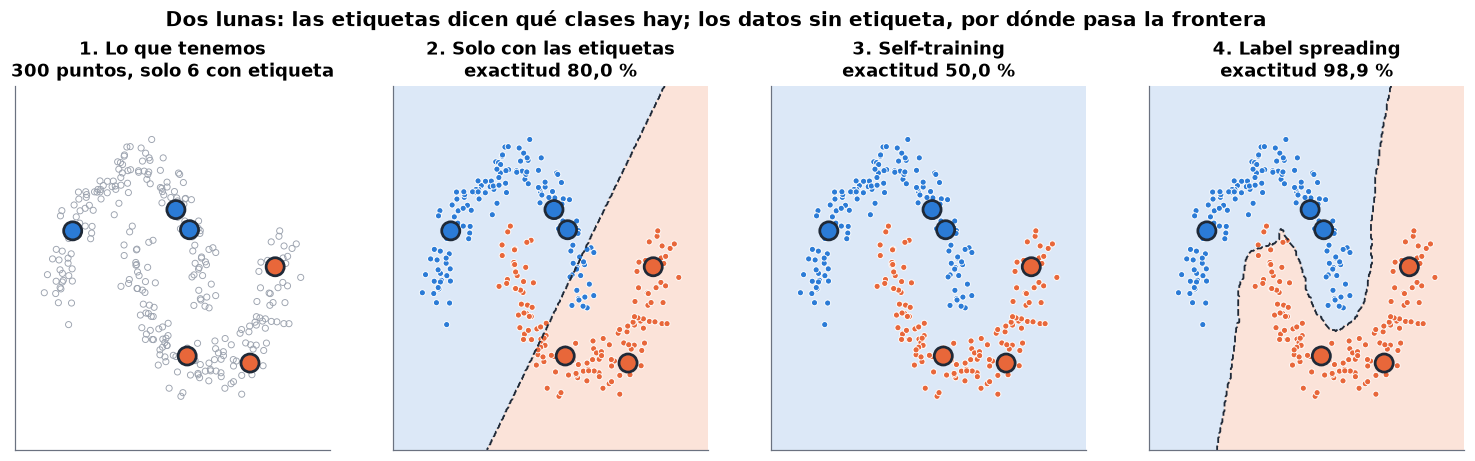

In [6]:
def plot_decision_regions(ax, model, X, y, labeled_idx, title, show_classes=True):
    # Regiones de decisión del modelo sobre una malla + puntos (grandes = etiquetados).
    x_min, x_max = X[:, 0].min() - 0.4, X[:, 0].max() + 0.4
    y_min, y_max = X[:, 1].min() - 0.4, X[:, 1].max() + 0.4
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    if model is not None:
        zz = predict(model, np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
        ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], colors=[LIGHT_BLUE, LIGHT_ORANGE])
        ax.contour(xx, yy, zz, levels=[0.5], colors=INK, linestyles="--", linewidths=1.2)
    point_colors = CLASS_COLORS[y] if show_classes else "none"
    edge_colors = "white" if show_classes else "#9CA3AF"
    ax.scatter(X[:, 0], X[:, 1], s=16, c=point_colors, edgecolors=edge_colors, linewidths=0.6)
    ax.scatter(X[labeled_idx, 0], X[labeled_idx, 1], s=140, c=CLASS_COLORS[y[labeled_idx]],
               edgecolors=INK, linewidths=1.8, zorder=3)
    ax.set(title=title, xticks=[], yticks=[], xlim=(x_min, x_max), ylim=(y_min, y_max))
    ax.grid(False)


fig, axes = plt.subplots(1, 4, figsize=(17, 4.3))
plot_decision_regions(axes[0], None, X_moons, y_moons, moons_labeled,
                      f"1. Lo que tenemos\n{MOONS_N_TRAIN} puntos, solo {len(moons_labeled)} con etiqueta",
                      show_classes=False)
panels = [("lr", "2. Solo con las etiquetas"), ("self_training", "3. Self-training"),
          ("label_spreading", "4. Label spreading")]
for ax, (name, title) in zip(axes[1:], panels):
    plot_decision_regions(ax, moons_models[name], X_moons, y_moons, moons_labeled,
                          f"{title}\nexactitud {pct(moons_accuracy[name])}")
fig.suptitle("Dos lunas: las etiquetas dicen qué clases hay; los datos sin etiqueta, por dónde pasa la frontera",
             y=1.04, fontsize=13, fontweight="bold")
save_figure(fig, "fig01_dos_lunas_fronteras")
plt.show()

**Interpretación.** Con solo 6 etiquetas, la regresión logística traza una recta (80,0 % de exactitud). Es la mejor frontera lineal que permiten esos 6 puntos, pero corta las dos lunas. Label spreading alcanza el 98,9 % porque su frontera rodea las lunas: se apoya en los 294 puntos sin etiqueta, que muestran dónde hay datos y dónde hay un hueco. En otras palabras, las etiquetas indican qué clases existen y los datos sin etiqueta indican por dónde debe pasar la frontera. El 1-NN supervisado (91,5 %) también supera a la recta porque sigue la forma local de los datos, pero con 6 puntos no puede reconstruir la forma completa de las lunas.

El resultado del panel 3 es menos intuitivo: el self-training empeora a la regresión logística hasta el 50 % y termina clasificando todo como azul. El self-training no cambia la familia del modelo, que sigue siendo lineal, y además se reentrena con sus propias predicciones. La tabla siguiente muestra cómo ocurre el colapso en cada iteración.

In [7]:
# Anatomía del self-training en las dos lunas: qué aceptó en cada iteración.
self_training_moons = moons_models["self_training"]
rows = []
for iteration in range(1, self_training_moons.n_iter_ + 1):
    accepted = self_training_moons.labeled_iter_ == iteration
    assigned = self_training_moons.transduction_[accepted]
    rows.append({
        "iteración": iteration,
        "pseudo-etiquetas aceptadas": int(accepted.sum()),
        "asignadas a azul (clase 0)": int(np.sum(assigned == 0)),
        "asignadas a naranja (clase 1)": int(np.sum(assigned == 1)),
        "incorrectas": int(np.sum(assigned != y_moons[accepted])),
    })
print(f"Condición de parada: {self_training_moons.termination_condition_}")
pd.DataFrame(rows).set_index("iteración")

Condición de parada: all_labeled


,pseudo-etiquetas aceptadas,asignadas a azul (clase 0),asignadas a naranja (clase 1),incorrectas
iteración,,,,
1,66,66,0,0
2,97,94,3,39
3,51,51,0,26
4,22,22,0,21
5,12,12,0,12
6,15,15,0,15
7,17,17,0,17
8,14,14,0,14


En la primera iteración el modelo acepta 66 pseudo-etiquetas y ninguna es incorrecta, pero todas son de la clase azul: con 6 puntos de entrenamiento, la regresión logística solo supera la confianza de 0,8 en un extremo del plano. Al reentrenar con 69 ejemplos azules y 3 naranjas, la frontera se desplaza hacia la clase naranja. En la iteración 2 ya hay 39 errores entre 97 pseudo-etiquetas, en la 4 son 21 de 22 y a partir de la 5 todas son incorrectas, hasta que no queda ningún punto sin etiquetar.

Este es el **sesgo de confirmación**: cada error aceptado desplaza la frontera en la dirección que produce el siguiente error. El ejemplo deja además una lección menos evidente. El problema no empezó con pseudo-etiquetas incorrectas, sino con pseudo-etiquetas **desbalanceadas**. En la parte 4 aparece el mismo mecanismo con los dígitos.

### 1.1 Cómo viajan las etiquetas por el grafo

Para ver cómo funciona label spreading, detenemos la propagación tras 1 y 4 iteraciones (cada iteración equivale a un salto por las aristas del grafo) y la comparamos con el resultado final. Un punto cuenta como "con etiqueta" cuando ya recibió información de alguna clase.

Tras 1 iteración    :  62 de 300 puntos con etiqueta (iteraciones ejecutadas: 1)
Tras 4 iteraciones  : 216 de 300 puntos con etiqueta (iteraciones ejecutadas: 4)
Al converger        : 300 de 300 puntos con etiqueta (iteraciones ejecutadas: 181)


Figura guardada en figures/fig02_propagacion_grafo.png


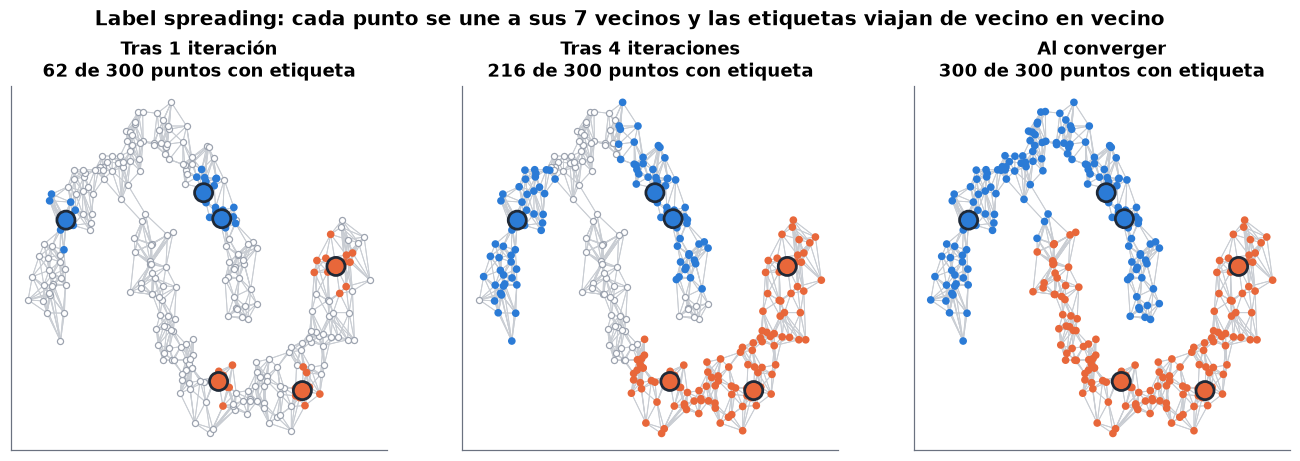

Etiquetas inferidas correctas para los 300 puntos de entrenamiento: 99,0 %


In [8]:
moons_graph = symmetric_knn_kernel(X_moons, X_moons).tocoo()
edges = np.stack([X_moons[moons_graph.row], X_moons[moons_graph.col]], axis=1)
y_moons_semi = hide_labels(y_moons, moons_labeled)

snapshots = []
for n_iter, title in [(1, "Tras 1 iteración"), (4, "Tras 4 iteraciones"), (LS_MAX_ITER, "Al converger")]:
    with warnings.catch_warnings():
        # Cortar la propagación antes de converger es intencional aquí.
        warnings.simplefilter("ignore", ConvergenceWarning)
        partial_model = make_label_spreading(max_iter=n_iter).fit(X_moons, y_moons_semi)
    reached = ~unreached_mask(partial_model)
    snapshots.append((title, partial_model, reached))
    print(f"{title:<20}: {reached.sum():>3} de {len(X_moons)} puntos con etiqueta "
          f"(iteraciones ejecutadas: {partial_model.n_iter_})")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, (title, partial_model, reached) in zip(axes, snapshots):
    ax.add_collection(LineCollection(edges, colors=LIGHT_GRAY, linewidths=0.6, zorder=1))
    ax.scatter(*X_moons[~reached].T, s=16, facecolors="white", edgecolors="#9CA3AF", linewidths=0.8, zorder=2)
    ax.scatter(*X_moons[reached].T, s=16, c=CLASS_COLORS[partial_model.transduction_[reached]], zorder=2)
    ax.scatter(*X_moons[moons_labeled].T, s=140, c=CLASS_COLORS[y_moons[moons_labeled]],
               edgecolors=INK, linewidths=1.8, zorder=3)
    ax.set(title=f"{title}\n{reached.sum()} de {len(X_moons)} puntos con etiqueta", xticks=[], yticks=[])
    ax.grid(False)
fig.suptitle("Label spreading: cada punto se une a sus 7 vecinos y las etiquetas viajan de vecino en vecino",
             y=1.04, fontsize=13, fontweight="bold")
save_figure(fig, "fig02_propagacion_grafo")
plt.show()

moons_inferred_accuracy = np.mean(moons_models["label_spreading"].transduction_ == y_moons)
print(f"Etiquetas inferidas correctas para los {MOONS_N_TRAIN} puntos de entrenamiento: {pct(moons_inferred_accuracy)}")

Tras una iteración, solo los vecinos directos de los 6 puntos etiquetados tienen información (62 de 300). Tras cuatro iteraciones son 216, y al converger (181 iteraciones) los 300 puntos tienen etiqueta, con un 99,0 % de aciertos. Cada etiqueta recorre su propia luna y casi no pasa a la otra porque muy pocas aristas cruzan el hueco entre ellas. Es el supuesto de clúster expresado como un grafo.

## 2. ¿Y si el supuesto de clúster no se cumple?

Si los datos no cumplen los supuestos del aprendizaje semisupervisado, los datos sin etiqueta pueden dejar de ayudar o incluso perjudicar. En las dos lunas podemos controlar cuánto se cumple el supuesto de clúster: al aumentar el ruido, las bandas se ensanchan, se solapan y desaparece la zona vacía entre las clases.

Para cuantificar el supuesto usamos la **concordancia de vecinos**: la fracción de los 7 vecinos más cercanos de cada punto que comparten su clase. Si es cercana al 100 %, "cerca" significa "misma clase" y el grafo es un buen conductor de etiquetas; si baja, el grafo conecta clases distintas.

Para cada nivel de ruido repetimos el experimento 30 veces (datos y etiquetas nuevos en cada repetición) con el mismo presupuesto de 6 etiquetas.

In [9]:
moons_records = []
for noise in MOONS_NOISE_LEVELS:
    for repetition in range(MOONS_REPETITIONS):
        seed = RANDOM_SEED + repetition
        X_train, y_train, X_test, y_test, labeled_idx = make_moons_problem(noise, seed)
        models = fit_all_methods(X_train, y_train, labeled_idx)
        moons_records.append({
            "ruido": noise,
            "repeticion": repetition,
            "concordancia_vecinos": neighbor_label_agreement(X_train, y_train),
            **test_accuracies(models, X_test, y_test),
        })
moons_sweep = pd.DataFrame(moons_records)
moons_sweep["ganancia_ls_vs_1nn"] = moons_sweep["label_spreading"] - moons_sweep["knn1"]
moons_sweep["ganancia_ls_vs_lr"] = moons_sweep["label_spreading"] - moons_sweep["lr"]

summary = moons_sweep.groupby("ruido").agg(
    concordancia=("concordancia_vecinos", "mean"),
    lr=("lr", "mean"), self_training=("self_training", "mean"),
    knn1=("knn1", "mean"), label_spreading=("label_spreading", "mean"),
    ls_gana_a_1nn=("ganancia_ls_vs_1nn", lambda g: f"{(g > 0).sum()}/{len(g)}"),
    ls_pierde_con_lr=("ganancia_ls_vs_lr", lambda g: f"{(g < 0).sum()}/{len(g)}"),
)
summary.style.format({col: "{:.1%}" for col in ["concordancia", "lr", "self_training", "knn1", "label_spreading"]})

,concordancia,lr,self_training,knn1,label_spreading,ls_gana_a_1nn,ls_pierde_con_lr
ruido,,,,,,,
0.050000,100.0%,81.2%,74.5%,86.1%,99.8%,30/30,0/30
0.100000,99.7%,81.0%,69.7%,84.6%,96.3%,29/30,0/30
0.150000,98.0%,80.4%,70.0%,82.3%,90.3%,27/30,2/30
0.200000,94.6%,79.6%,68.4%,79.4%,85.1%,22/30,3/30
0.250000,90.2%,78.3%,71.5%,76.4%,81.6%,22/30,7/30
0.300000,85.9%,76.6%,70.6%,73.7%,78.5%,22/30,7/30
0.400000,78.5%,73.5%,69.7%,69.9%,75.1%,23/30,8/30
0.500000,73.5%,70.8%,68.3%,67.2%,70.8%,24/30,10/30


Figura guardada en figures/fig03_supuesto_cluster_ruido.png


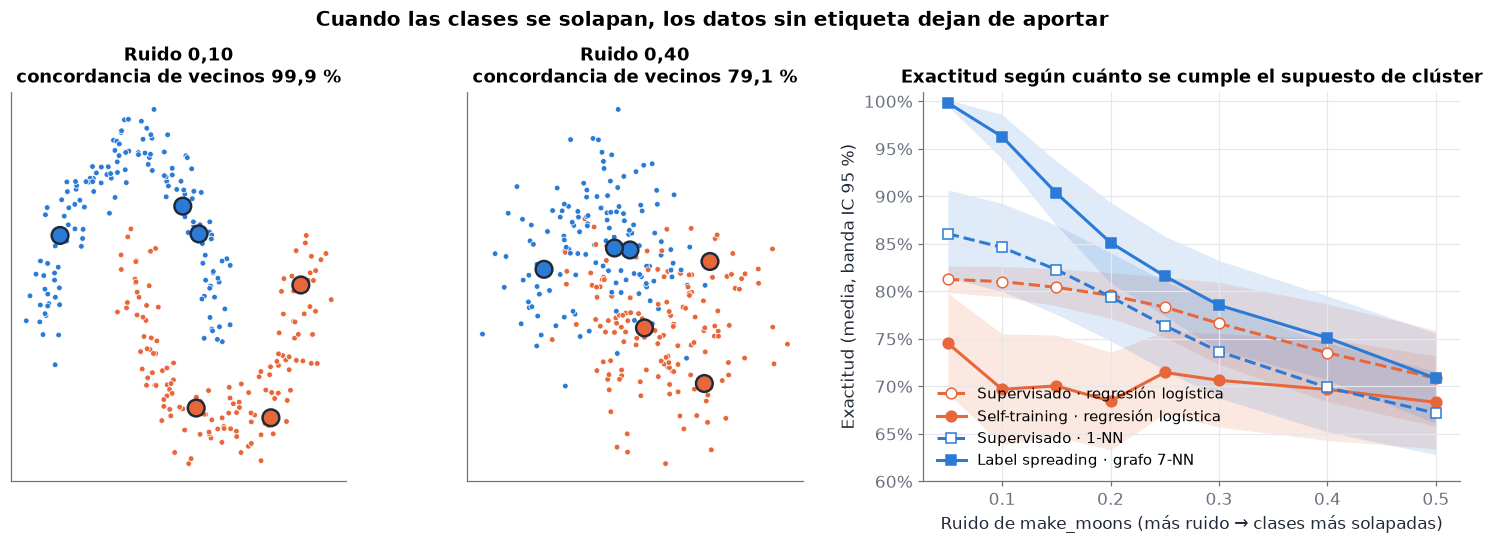

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1, 1, 1.6], "wspace": 0.3})
for ax, noise in zip(axes[:2], [0.10, 0.40]):
    X_example, y_example, _, _, labeled_example = make_moons_problem(noise, RANDOM_SEED)
    agreement = neighbor_label_agreement(X_example, y_example)
    ax.scatter(*X_example.T, s=14, c=CLASS_COLORS[y_example], edgecolors="white", linewidths=0.5)
    ax.scatter(*X_example[labeled_example].T, s=120, c=CLASS_COLORS[y_example[labeled_example]],
               edgecolors=INK, linewidths=1.6)
    ax.set(title=f"Ruido {noise:.2f}\nconcordancia de vecinos {pct(agreement)}".replace(".", ","),
           xticks=[], yticks=[])
    ax.grid(False)

grouped = moons_sweep.groupby("ruido")
noise_values = np.array(MOONS_NOISE_LEVELS)
for method in METHODS:
    plot_method(axes[2], noise_values, grouped[method], method)
axes[2].set(xlabel="Ruido de make_moons (más ruido → clases más solapadas)",
            ylabel="Exactitud (media, banda IC 95 %)",
            title="Exactitud según cuánto se cumple el supuesto de clúster", ylim=(0.6, 1.01))
axes[2].yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0, decimals=0))
axes[2].legend(loc="lower left", fontsize=9.5)
fig.suptitle("Cuando las clases se solapan, los datos sin etiqueta dejan de aportar", y=1.04,
             fontsize=13, fontweight="bold")
save_figure(fig, "fig03_supuesto_cluster_ruido")
plt.show()

**Interpretación.** Con ruido 0,05 la concordancia de vecinos es del 100 % y label spreading (99,8 %) supera ampliamente a la regresión logística (81,2 %) y al 1-NN (86,1 %). A medida que aumenta el ruido, la concordancia baja y la ventaja se reduce. Con ruido 0,5 (concordancia del 73,5 %), label spreading empata en promedio con la regresión logística (70,8 % en ambos casos) y pierde frente a ella en 10 de las 30 repeticiones. Cuando las clases se solapan, el grafo conecta puntos de clases distintas y las etiquetas se propagan hacia la clase equivocada.

Conviene precisar dos aspectos:

1. En promedio, label spreading no llega a ser peor que el mejor método supervisado. En este experimento, el incumplimiento del supuesto se traduce en la pérdida de la ventaja y en un mayor riesgo en repeticiones individuales, no en un empeoramiento sistemático.
2. El self-training sí empeora a la regresión logística en todos los niveles de ruido (68–75 % frente a 71–81 %). En este caso el problema no es el supuesto de clúster, sino la capacidad del modelo base: una recta no puede seguir la forma de las lunas, y el self-training amplifica ese sesgo en lugar de corregirlo.

## 3. Experimento principal: dígitos escritos a mano

### 3.1 El conjunto de datos

| | |
|---|---|
| **Nombre** | *Optical Recognition of Handwritten Digits* |
| **Procedencia** | UCI Machine Learning Repository (Alpaydin y Kaynak, 1998) · DOI [10.24432/C50P49](https://doi.org/10.24432/C50P49) |
| **Acceso reproducible** | `sklearn.datasets.load_digits()` — scikit-learn incluye una copia del conjunto de prueba de UCI, sin descarga |
| **Contenido** | 1.797 imágenes de 8 × 8 píxeles de dígitos 0–9 escritos por distintas personas. Cada píxel es el número de píxeles negros (0–16) de un bloque 4 × 4 del mapa de bits original de 32 × 32 |
| **Tarea** | Clasificación en 10 clases a partir de 64 variables |

**Por qué elegimos este conjunto.** Es una tarea real de visión por computador, con 10 clases y 64 variables, en el tipo de dominio donde más se usa el aprendizaje semisupervisado. Etiquetar dígitos es un caso típico de anotación manual, y aquí podemos simular que solo unas decenas de imágenes están etiquetadas mientras conservamos las etiquetas verdaderas para evaluar. Además, su tamaño permite repetir cada experimento 20 veces en pocos minutos y medir así la variabilidad de los resultados. También consideramos MNIST (OpenML 554, 70.000 imágenes), más cercano a las aplicaciones reales, pero requiere descarga y mucho más tiempo de cómputo sin cambiar los mecanismos que queremos estudiar.

Las variables se usan en su escala original (0–16). En los métodos basados en vecinos la escala no importa, porque multiplicar todas las distancias por la misma constante no cambia quién es vecino de quién. En la regresión logística sí importa, y en la parte 4 veremos por qué esto es relevante para el self-training.

Imágenes: 1797 · variables: 64 · rango de valores: 0–16
Imágenes por clase: {0: 178, 1: 182, 2: 177, 3: 183, 4: 181, 5: 182, 6: 181, 7: 179, 8: 174, 9: 180}


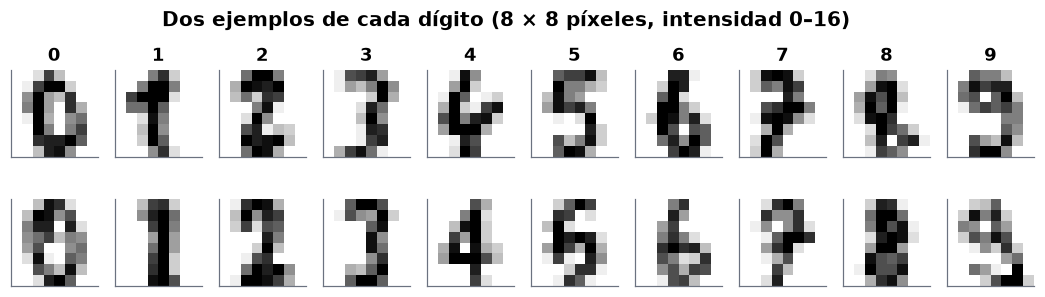

In [11]:
digits = load_digits()
X_digits, y_digits = digits.data, digits.target
CLASSES = np.unique(y_digits)
N_CLASSES = len(CLASSES)

print(f"Imágenes: {X_digits.shape[0]} · variables: {X_digits.shape[1]} · rango de valores: "
      f"{X_digits.min():.0f}–{X_digits.max():.0f}")
print("Imágenes por clase:", dict(zip(CLASSES.tolist(), np.bincount(y_digits).tolist())))

fig, axes = plt.subplots(2, 10, figsize=(12, 2.8))
rng_examples = np.random.default_rng(RANDOM_SEED)
for digit in CLASSES:
    for row in range(2):
        index = rng_examples.choice(np.flatnonzero(y_digits == digit))
        axes[row, digit].imshow(digits.images[index], cmap="gray_r", vmin=0, vmax=16)
        axes[row, digit].set(xticks=[], yticks=[])
        axes[row, digit].grid(False)
    axes[0, digit].set_title(str(digit))
fig.suptitle("Dos ejemplos de cada dígito (8 × 8 píxeles, intensidad 0–16)", y=1.04, fontweight="bold")
plt.show()

**¿Cumplen los dígitos los supuestos?** Antes de esperar algo del aprendizaje semisupervisado, lo comprobamos con la misma concordancia de vecinos de la parte 2. Además verificamos la cobertura del grafo, que motivó los dos ajustes a label spreading descritos en las herramientas comunes: qué fracción de las imágenes de entrenamiento recibe alguna etiqueta con 10 etiquetas (el caso más difícil) bajo distintas configuraciones. Esta comprobación no usa el conjunto de prueba.

In [12]:
digits_agreement = neighbor_label_agreement(X_digits, y_digits)
print(f"Concordancia de vecinos en dígitos (k = {N_NEIGHBORS}): {pct(digits_agreement)}")
moons_reference = moons_sweep.groupby("ruido")["concordancia_vecinos"].mean()
print("Concordancia en las dos lunas, como referencia:",
      ", ".join(f"ruido {n:.2f} → {pct(a)}" for n, a in moons_reference.items()))

graph_configurations = {
    "scikit-learn por defecto: grafo dirigido, α = 0,2": dict(kernel="knn", n_neighbors=N_NEIGHBORS, alpha=0.2),
    "grafo dirigido, α = 0,99": dict(kernel="knn", n_neighbors=N_NEIGHBORS, alpha=ALPHA, max_iter=LS_MAX_ITER),
    "grafo simétrico, α = 0,99 (usado aquí)": dict(kernel=symmetric_knn_kernel, alpha=ALPHA, max_iter=LS_MAX_ITER),
}
coverage_records = []
for repetition in range(5):
    seed = RANDOM_SEED + repetition
    X_train, _, y_train, _ = train_test_split(X_digits, y_digits, test_size=TEST_SIZE,
                                              stratify=y_digits, random_state=seed)
    labeled_idx = sample_labeled_indices(y_train, 1, np.random.default_rng(seed))
    for name, params in graph_configurations.items():
        model = LabelSpreading(**params).fit(X_train, hide_labels(y_train, labeled_idx))
        coverage_records.append({"Configuración": name, "iteraciones": model.n_iter_,
                                 "imágenes sin ninguna etiqueta": unreached_mask(model).sum()})
coverage = pd.DataFrame(coverage_records).groupby("Configuración", sort=False).mean()
coverage["% del entrenamiento alcanzado"] = 1 - coverage["imágenes sin ninguna etiqueta"] / len(y_train)
coverage.style.format({"iteraciones": "{:.0f}", "imágenes sin ninguna etiqueta": "{:.1f}",
                       "% del entrenamiento alcanzado": "{:.1%}"})

Concordancia de vecinos en dígitos (k = 7): 97,3 %
Concordancia en las dos lunas, como referencia: ruido 0.05 → 100,0 %, ruido 0.10 → 99,7 %, ruido 0.15 → 98,0 %, ruido 0.20 → 94,6 %, ruido 0.25 → 90,2 %, ruido 0.30 → 85,9 %, ruido 0.40 → 78,5 %, ruido 0.50 → 73,5 %


,iteraciones,imágenes sin ninguna etiqueta,% del entrenamiento alcanzado
Configuración,,,
"scikit-learn por defecto: grafo dirigido, α = 0,2",6,255.0,79.7%
"grafo dirigido, α = 0,99",548,4.2,99.7%
"grafo simétrico, α = 0,99 (usado aquí)",260,0.0,100.0%


**Los dígitos cumplen el supuesto de suavidad.** El 97,3 % de los 7 vecinos de cada imagen corresponden al mismo dígito. En la escala de las dos lunas, eso equivale a un ruido de entre 0,15 y 0,2, la zona en la que label spreading tenía una ventaja clara. Antes de entrenar cualquier modelo podemos anticipar que un método basado en grafos debería funcionar bien. En un caso real esta medida solo podría estimarse con las pocas etiquetas disponibles, pero sirve como diagnóstico.

**La tabla de cobertura justifica las dos decisiones de implementación.** Con la configuración por defecto de scikit-learn, la propagación se detiene tras 6 iteraciones y deja sin etiqueta a 255 de las 1.257 imágenes de entrenamiento (el 20 %), a las que `transduction_` asigna la clase 0 sin ninguna advertencia. Con α = 0,99, el grafo dirigido todavía deja unas 4 imágenes sin alcanzar; con el grafo simétrico, la cobertura es completa.

### 3.2 Protocolo experimental

Para cada presupuesto de etiquetas (10, 20, 50, 100 y 200) y cada una de las 20 repeticiones:

1. Se divide el conjunto en entrenamiento (1.257 imágenes) y prueba (540), estratificando por clase. La semilla cambia en cada repetición, así que cambian tanto la partición como las etiquetas elegidas.
2. Dentro del entrenamiento se conservan las etiquetas de $n/10$ imágenes por clase; las demás se marcan con −1.
3. Se entrenan los cuatro métodos con **las mismas** etiquetas: dos supervisados, que solo ven las imágenes etiquetadas, y dos semisupervisados, que además ven todas las imágenes sin etiqueta.
4. Se mide la exactitud en las 540 imágenes de prueba, que ningún método ve durante el entrenamiento.

Como referencia superior, en cada repetición también se entrenan la regresión logística y el 1-NN con las 1.257 etiquetas: es lo que obtendríamos si pagáramos por etiquetarlo todo.

In [13]:
def split_digits(seed, X=X_digits, y=y_digits):
    return train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=seed)


def run_digits_repetition(n_labels, seed):
    # Una repetición del experimento: misma partición y mismas etiquetas para los cuatro métodos.
    X_train, X_test, y_train, y_test = split_digits(seed)
    labeled_idx = sample_labeled_indices(y_train, n_labels // N_CLASSES, np.random.default_rng(seed))
    models = fit_all_methods(X_train, y_train, labeled_idx)

    n_pseudo, pseudo_error = pseudo_label_stats(models["self_training"], y_train)
    spreading = models["label_spreading"]
    unlabeled = np.setdiff1d(np.arange(len(y_train)), labeled_idx)
    inferred = np.where(unreached_mask(spreading), UNLABELED, spreading.transduction_)
    return {
        "n_etiquetas": n_labels,
        "semilla": seed,
        **test_accuracies(models, X_test, y_test),
        "st_pseudo_etiquetas": n_pseudo,
        "st_error_pseudo": pseudo_error,
        "ls_error_inferidas": np.mean(inferred[unlabeled] != y_train[unlabeled]),
        "ls_prueba_sin_informacion": int(np.sum(predict(spreading, X_test) == UNLABELED)),
    }


start = time.perf_counter()
digits_results = pd.DataFrame([
    run_digits_repetition(n_labels, RANDOM_SEED + repetition)
    for n_labels in LABEL_BUDGETS
    for repetition in range(N_REPETITIONS)
])

reference_records = []
for repetition in range(N_REPETITIONS):
    X_train, X_test, y_train, y_test = split_digits(RANDOM_SEED + repetition)
    reference_records.append({
        "lr_todas": make_logistic_regression().fit(X_train, y_train).score(X_test, y_test),
        "knn1_todas": KNeighborsClassifier(n_neighbors=1).fit(X_train, y_train).score(X_test, y_test),
    })
references = pd.DataFrame(reference_records)
print(f"{len(digits_results)} entrenamientos de 4 métodos en {time.perf_counter() - start:.0f} s")

100 entrenamientos de 4 métodos en 79 s


In [14]:
def mean_std(values):
    return f"{pct(values.mean())} ± {100 * values.std():.1f}".replace(".", ",")


accuracy_table = digits_results.groupby("n_etiquetas")[list(METHODS)].agg(mean_std)
accuracy_table.columns = [METHODS[name]["label"] for name in METHODS]
accuracy_table.index.name = "Etiquetas"
print("Referencia con las 1.257 etiquetas: "
      f"regresión logística {mean_std(references['lr_todas'])} · 1-NN {mean_std(references['knn1_todas'])}")
accuracy_table

Referencia con las 1.257 etiquetas: regresión logística 96,2 % ± 0,6 · 1-NN 98,8 % ± 0,3


,Supervisado · regresión logística,Self-training · regresión logística,Supervisado · 1-NN,Label spreading · grafo 7-NN
Etiquetas,,,,
10,"65,7 % ± 5,3","73,7 % ± 6,4","65,7 % ± 5,8","88,8 % ± 3,9"
20,"75,8 % ± 5,0","81,5 % ± 5,3","74,9 % ± 5,5","90,8 % ± 3,5"
50,"85,9 % ± 2,3","88,8 % ± 1,8","86,4 % ± 2,4","94,1 % ± 2,0"
100,"89,9 % ± 1,7","91,3 % ± 1,6","91,5 % ± 1,8","95,7 % ± 1,7"
200,"93,0 % ± 1,4","93,8 % ± 1,5","95,3 % ± 1,2","95,8 % ± 1,1"


### 3.3 Resultados con 50 etiquetas

Para cada par "semisupervisado frente a su contraparte supervisada" calculamos la **diferencia pareada** de exactitud en cada repetición (misma partición, mismas etiquetas), su media con un intervalo de confianza del 95 % (distribución *t* de Student sobre las 20 diferencias) y en cuántas repeticiones gana el método semisupervisado.

In [15]:
def paired_gains(results, comparisons):
    # Diferencias pareadas (en puntos porcentuales) entre métodos evaluados sobre las mismas repeticiones.
    rows = []
    for n_labels, group in results.groupby("n_etiquetas"):
        for method, baseline in comparisons.items():
            differences = 100 * (group[method] - group[baseline]).to_numpy()
            mean = differences.mean()
            half_width = stats.t.ppf(0.975, len(differences) - 1) * stats.sem(differences)
            rows.append({
                "n_etiquetas": n_labels,
                "comparación": f"{METHODS[method]['label']}  vs  {METHODS[baseline]['label']}",
                "método": method,
                "ganancia_pp": mean,
                "ic95_inf": mean - half_width,
                "ic95_sup": mean + half_width,
                "gana": f"{(differences > 0).sum()}/{len(differences)}",
                "pierde": f"{(differences < 0).sum()}/{len(differences)}",
            })
    return pd.DataFrame(rows)


gains = paired_gains(digits_results, PAIRS)
# Comparación adicional entre familias: label spreading frente a la regresión logística.
gains_vs_lr = paired_gains(digits_results, {"label_spreading": "lr"})

main = digits_results[digits_results["n_etiquetas"] == MAIN_BUDGET]
print(f"Con {MAIN_BUDGET} etiquetas ({N_REPETITIONS} repeticiones):")
print(f"  self-training aceptó en promedio {main['st_pseudo_etiquetas'].mean():.0f} pseudo-etiquetas "
      f"de 1.207 posibles, con {pct(main['st_error_pseudo'].mean())} de error")
print(f"  label spreading etiquetó las 1.207 imágenes sin etiqueta con {pct(main['ls_error_inferidas'].mean())} de error")
print(f"  imágenes de prueba sin información en el grafo (cuentan como error): "
      f"{main['ls_prueba_sin_informacion'].mean():.1f} de 540 en promedio")
(pd.concat([gains, gains_vs_lr])
   .query("n_etiquetas == @MAIN_BUDGET")
   .drop(columns=["n_etiquetas", "método"])
   .style.format({"ganancia_pp": "{:+.1f}", "ic95_inf": "{:+.1f}", "ic95_sup": "{:+.1f}"})
   .hide(axis="index"))

Con 50 etiquetas (20 repeticiones):
  self-training aceptó en promedio 1182 pseudo-etiquetas de 1.207 posibles, con 10,3 % de error
  label spreading etiquetó las 1.207 imágenes sin etiqueta con 6,0 % de error
  imágenes de prueba sin información en el grafo (cuentan como error): 0.3 de 540 en promedio


comparación,ganancia_pp,ic95_inf,ic95_sup,gana,pierde
Self-training · regresión logística vs Supervisado · regresión logística,+2.9,+2.1,+3.7,19/20,1/20
Label spreading · grafo 7-NN vs Supervisado · 1-NN,+7.7,+6.6,+8.9,20/20,0/20
Label spreading · grafo 7-NN vs Supervisado · regresión logística,+8.2,+7.2,+9.2,20/20,0/20


Figura guardada en figures/fig04_resultados_50_etiquetas.png


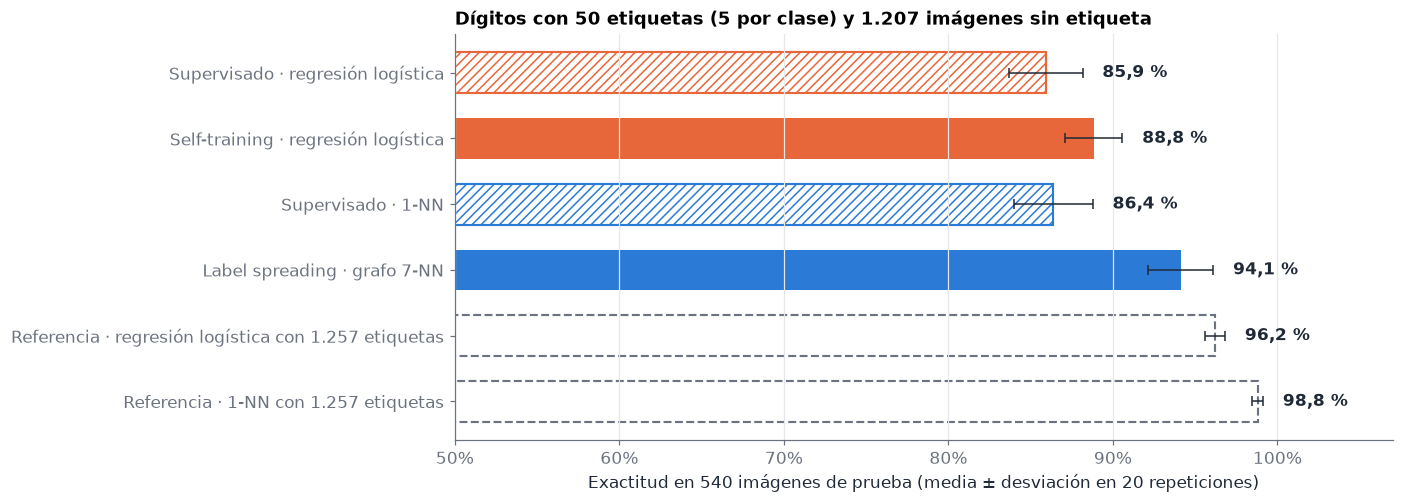

In [16]:
fig, ax = plt.subplots(figsize=(11, 4.8))
bars = [(METHODS[name]["label"], main[name], METHODS[name]["color"], name in PAIRS) for name in METHODS]
bars += [("Referencia · regresión logística con 1.257 etiquetas", references["lr_todas"], GRAY, None),
         ("Referencia · 1-NN con 1.257 etiquetas", references["knn1_todas"], GRAY, None)]
for position, (label, values, color, uses_unlabeled) in enumerate(bars):
    y_pos = len(bars) - 1 - position
    if uses_unlabeled is None:        # referencias: barra hueca
        style = dict(facecolor="white", edgecolor=color, linestyle="--", linewidth=1.4)
    elif uses_unlabeled:              # semisupervisado: barra llena
        style = dict(color=color)
    else:                             # supervisado con 50 etiquetas: barra rayada
        style = dict(facecolor="white", edgecolor=color, hatch="////", linewidth=1.4)
    ax.barh(y_pos, values.mean(), height=0.62, xerr=values.std(),
            error_kw=dict(ecolor=INK, capsize=3, linewidth=1), **style)
    ax.text(values.mean() + values.std() + 0.012, y_pos, pct(values.mean()), va="center",
            fontsize=11, fontweight="bold", color=INK)
ax.set_yticks(range(len(bars)))
ax.set_yticklabels([label for label, *_ in bars][::-1])
ax.set_xlim(0.5, 1.07)
ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
ax.set_xlabel("Exactitud en 540 imágenes de prueba (media ± desviación en 20 repeticiones)")
ax.set_title(f"Dígitos con {MAIN_BUDGET} etiquetas (5 por clase) y 1.207 imágenes sin etiqueta", loc="left")
ax.grid(axis="y", visible=False)
save_figure(fig, "fig04_resultados_50_etiquetas")
plt.show()

**Interpretación.** Los dos métodos semisupervisados superan a su contraparte supervisada, y en ambos casos el intervalo de confianza excluye el cero.

- **Self-training: +2,9 pp** sobre la regresión logística (IC 95 %: 2,1 a 3,7), con mejor resultado en 19 de 20 repeticiones. Acepta casi todas las imágenes sin etiqueta (1.182 de 1.207), pero el 10,3 % de sus pseudo-etiquetas son incorrectas: el modelo aprende de unos 120 errores propios, lo que limita la ganancia.
- **Label spreading: +7,7 pp** sobre 1-NN (IC 95 %: 6,6 a 8,9), con mejor resultado en las 20 repeticiones. Etiqueta las 1.207 imágenes con un error de solo 6,0 % y queda a 2,1 puntos de una regresión logística entrenada con las 1.257 etiquetas, aunque usa apenas el 4 % de ellas.

Label spreading obtiene una ganancia mayor porque aprovecha directamente la geometría de los datos (97 % de concordancia de vecinos), mientras que el self-training solo amplía el conjunto de entrenamiento con lo que la regresión logística ya predecía.

**Sobre la comparación entre familias de modelos.** Si comparáramos label spreading con la regresión logística, parte de la diferencia se debería al tipo de modelo y no a los datos sin etiqueta: en este conjunto los métodos de vecinos funcionan muy bien (1-NN con todas las etiquetas: 98,8 %; regresión logística: 96,2 %). Con 50 etiquetas ambos supervisados están parejos (86,4 % y 85,9 %), así que la diferencia es pequeña (+7,7 frente a +8,2 pp). Con 200 etiquetas, en cambio, el 1-NN ya supera a la regresión logística por 2,3 pp, y usarla como referencia exageraría el aporte de los datos sin etiqueta.

### 3.4 ¿Cómo cambia la ganancia con el número de etiquetas?

Si ya se dispone de suficientes etiquetas, cabe esperar que los datos sin etiqueta aporten poco. La curva de aprendizaje permite ver dónde está ese límite en este problema. A la izquierda se muestra la exactitud de cada método según el número de etiquetas; a la derecha, la ganancia pareada de cada método semisupervisado sobre su contraparte supervisada, con su intervalo de confianza del 95 %.

Figura guardada en figures/fig05_curva_aprendizaje.png


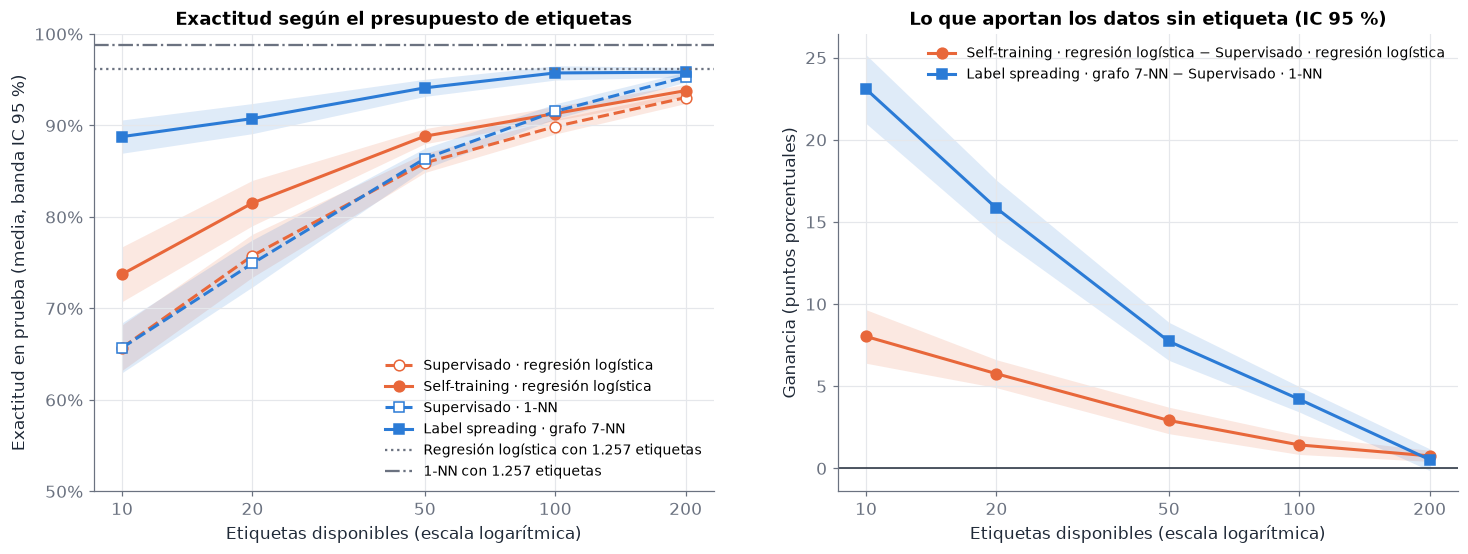

,ganancia_pp_label_spreading,ganancia_pp_self_training,ic95_inf_label_spreading,ic95_inf_self_training,ic95_sup_label_spreading,ic95_sup_self_training,gana_label_spreading,gana_self_training,st_pseudo_etiquetas,st_error_pseudo,ls_error_inferidas
n_etiquetas,,,,,,,,,,,
10,+23.1,+8.0,+21.0,+6.4,+25.2,+9.7,20/20,19/20,1215,24.9%,11.2%
20,+15.8,+5.8,+14.1,+4.9,+17.5,+6.6,20/20,20/20,1206,17.5%,9.6%
50,+7.7,+2.9,+6.6,+2.1,+8.9,+3.7,20/20,19/20,1182,10.3%,6.0%
100,+4.2,+1.4,+3.4,+0.8,+5.0,+2.0,20/20,17/20,1132,7.4%,4.3%
200,+0.5,+0.8,-0.1,+0.4,+1.2,+1.1,11/20,15/20,1036,5.2%,4.2%


In [17]:
fig, (ax_acc, ax_gain) = plt.subplots(1, 2, figsize=(16, 5.4))
grouped = digits_results.groupby("n_etiquetas")
for method in METHODS:
    plot_method(ax_acc, LABEL_BUDGETS, grouped[method], method)
for column, label, linestyle in [("lr_todas", "Regresión logística con 1.257 etiquetas", ":"),
                                 ("knn1_todas", "1-NN con 1.257 etiquetas", "-.")]:
    ax_acc.axhline(references[column].mean(), color=GRAY, linestyle=linestyle, linewidth=1.5, label=label)
ax_acc.set(xscale="log", xlabel="Etiquetas disponibles (escala logarítmica)",
           ylabel="Exactitud en prueba (media, banda IC 95 %)",
           title="Exactitud según el presupuesto de etiquetas", ylim=(0.5, 1.0))
ax_acc.set_xticks(LABEL_BUDGETS, [str(n) for n in LABEL_BUDGETS])
ax_acc.minorticks_off()
ax_acc.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
ax_acc.legend(loc="lower right", fontsize=9)

for method in PAIRS:
    subset = gains[gains["método"] == method]
    style = METHODS[method]
    ax_gain.plot(subset["n_etiquetas"], subset["ganancia_pp"], color=style["color"], marker=style["marker"],
                 linewidth=2, markersize=7, label=subset["comparación"].iloc[0].replace("  vs  ", " − "))
    ax_gain.fill_between(subset["n_etiquetas"], subset["ic95_inf"], subset["ic95_sup"],
                         color=style["color"], alpha=0.15, linewidth=0)
ax_gain.axhline(0, color=INK, linewidth=1)
ax_gain.set(xscale="log", xlabel="Etiquetas disponibles (escala logarítmica)",
            ylabel="Ganancia (puntos porcentuales)", title="Lo que aportan los datos sin etiqueta (IC 95 %)")
ax_gain.set_xticks(LABEL_BUDGETS, [str(n) for n in LABEL_BUDGETS])
ax_gain.minorticks_off()
ax_gain.legend(loc="upper right", fontsize=9)
save_figure(fig, "fig05_curva_aprendizaje")
plt.show()

# Ganancias pareadas y calidad de las etiquetas que cada método infiere para las imágenes sin etiqueta.
quality = digits_results.groupby("n_etiquetas").agg(
    st_pseudo_etiquetas=("st_pseudo_etiquetas", "mean"),
    st_error_pseudo=("st_error_pseudo", "mean"),
    ls_error_inferidas=("ls_error_inferidas", "mean"),
)
gains_wide = gains.pivot(index="n_etiquetas", columns="método", values=["ganancia_pp", "ic95_inf", "ic95_sup", "gana"])
gains_wide.columns = [f"{value}_{method}" for value, method in gains_wide.columns]
gains_wide.join(quality).style.format({
    **{column: "{:+.1f}" for column in gains_wide.columns if column.startswith(("ganancia", "ic95"))},
    "st_pseudo_etiquetas": "{:.0f}", "st_error_pseudo": "{:.1%}", "ls_error_inferidas": "{:.1%}"})

**Interpretación.** La ganancia es grande cuando las etiquetas escasean y desaparece cuando abundan.

- Con **10 etiquetas** (una por dígito), label spreading pasa del 65,7 % al 88,8 % (+23,1 pp) y el self-training del 65,7 % al 73,7 % (+8,0 pp).
- Con **200 etiquetas**, las ganancias caen a +0,5 y +0,8 pp. Label spreading supera al 1-NN en solo 11 de 20 repeticiones y su intervalo de confianza incluye el cero (−0,1 a +1,2), por lo que ya no hay evidencia de que los datos sin etiqueta le aporten. El self-training mantiene una mejora pequeña pero consistente (IC 95 %: +0,4 a +1,1), sin relevancia práctica frente a la que obtenía con pocas etiquetas.

En términos de costo de etiquetado, label spreading con 50 etiquetas (94,1 %) supera a los dos métodos supervisados con 100 etiquetas (89,9 % y 91,5 %) y a la regresión logística con 200 (93,0 %). En este problema, aprovechar las imágenes sin etiqueta equivale a más que duplicar el presupuesto de etiquetado.

La tabla muestra también la calidad de las etiquetas inferidas. El error de las pseudo-etiquetas del self-training baja del 24,9 % con 10 etiquetas al 5,2 % con 200, y el de label spreading del 11,2 % al 4,2 %; label spreading infiere etiquetas más limpias en todos los casos. Con pocas etiquetas, el self-training se entrena con una de cada cuatro pseudo-etiquetas equivocada y aun así mejora (+8,0 pp), porque el modelo inicial es tan débil que incluso datos ruidosos le aportan información. Con muchas etiquetas ocurre lo contrario: las pseudo-etiquetas son limpias, pero el modelo supervisado ya es bueno y queda poco por mejorar.

## 4. Self-training al microscopio: el umbral y el sesgo de confirmación

En el self-training, el umbral de confianza controla un compromiso: un umbral alto acepta pocas pseudo-etiquetas pero más limpias, y uno bajo acepta muchas pero con más errores. Además existe el riesgo de **sesgo de confirmación**: un error aceptado pasa a ser dato de entrenamiento. En esta parte lo medimos con 50 etiquetas y umbrales entre 0,5 y 0,99.

Estudiamos también una segunda variable que suele pasarse por alto: **la calibración del modelo base**. El umbral se aplica sobre las probabilidades que produce la regresión logística, y esas probabilidades dependen de detalles aparentemente inofensivos. Comparamos la misma regresión logística con los píxeles en su escala original (0–16) y reescalados a 0–1 (divididos entre 16), una normalización muy habitual. Con regularización L2, dividir las variables entre 16 equivale a regularizar 256 veces más, lo que produce probabilidades menos extremas: el mismo umbral de 0,8 pasa a significar algo distinto.

In [18]:
PIXEL_SCALES = {"píxeles 0–16 (escala original)": 1.0, "píxeles 0–1 (÷ 16)": 1 / 16}
SCALE_STYLES = {"píxeles 0–16 (escala original)": dict(color=ORANGE, linestyle="-", marker="o"),
                "píxeles 0–1 (÷ 16)": dict(color=INK, linestyle="--", marker="s")}


def run_threshold_repetition(scale_name, seed, n_labels=MAIN_BUDGET):
    # Self-training con varios umbrales sobre la misma partición y las mismas etiquetas.
    X_train, X_test, y_train, y_test = split_digits(seed, X=X_digits * PIXEL_SCALES[scale_name])
    labeled_idx = sample_labeled_indices(y_train, n_labels // N_CLASSES, np.random.default_rng(seed))
    y_semi = hide_labels(y_train, labeled_idx)
    supervised = make_logistic_regression().fit(X_train[labeled_idx], y_train[labeled_idx])
    supervised_accuracy = supervised.score(X_test, y_test)

    records = []
    for threshold in THRESHOLDS:
        self_training = make_self_training(threshold).fit(X_train, y_semi)
        n_pseudo, pseudo_error = pseudo_label_stats(self_training, y_train)
        accepted = self_training.labeled_iter_ > 0
        records.append({
            "escala": scale_name,
            "semilla": seed,
            "umbral": threshold,
            "pseudo_etiquetas": n_pseudo,
            "error_pseudo": pseudo_error,
            "exactitud": self_training.score(X_test, y_test),
            "ganancia_pp": 100 * (self_training.score(X_test, y_test) - supervised_accuracy),
            "pseudo_por_clase": np.bincount(self_training.transduction_[accepted], minlength=N_CLASSES),
            "recall_st": recall_score(y_test, self_training.predict(X_test), average=None),
            "recall_supervisado": recall_score(y_test, supervised.predict(X_test), average=None),
        })
    return records


start = time.perf_counter()
threshold_results = pd.DataFrame([
    record
    for scale_name in PIXEL_SCALES
    for repetition in range(N_REPETITIONS)
    for record in run_threshold_repetition(scale_name, RANDOM_SEED + repetition)
])
print(f"{len(threshold_results)} entrenamientos de self-training en {time.perf_counter() - start:.0f} s")

threshold_summary = threshold_results.groupby(["escala", "umbral"], sort=False).agg(
    pseudo_etiquetas=("pseudo_etiquetas", "mean"),
    error_pseudo=("error_pseudo", "mean"),
    exactitud=("exactitud", "mean"),
    ganancia_pp=("ganancia_pp", "mean"),
    repeticiones_que_gana=("ganancia_pp", lambda g: f"{(g > 0).sum()}/{len(g)}"),
)
threshold_summary.style.format({"pseudo_etiquetas": "{:.0f}", "error_pseudo": "{:.1%}",
                                "exactitud": "{:.1%}", "ganancia_pp": "{:+.1f}"})

280 entrenamientos de self-training en 103 s


Figura guardada en figures/fig06_umbral_self_training.png


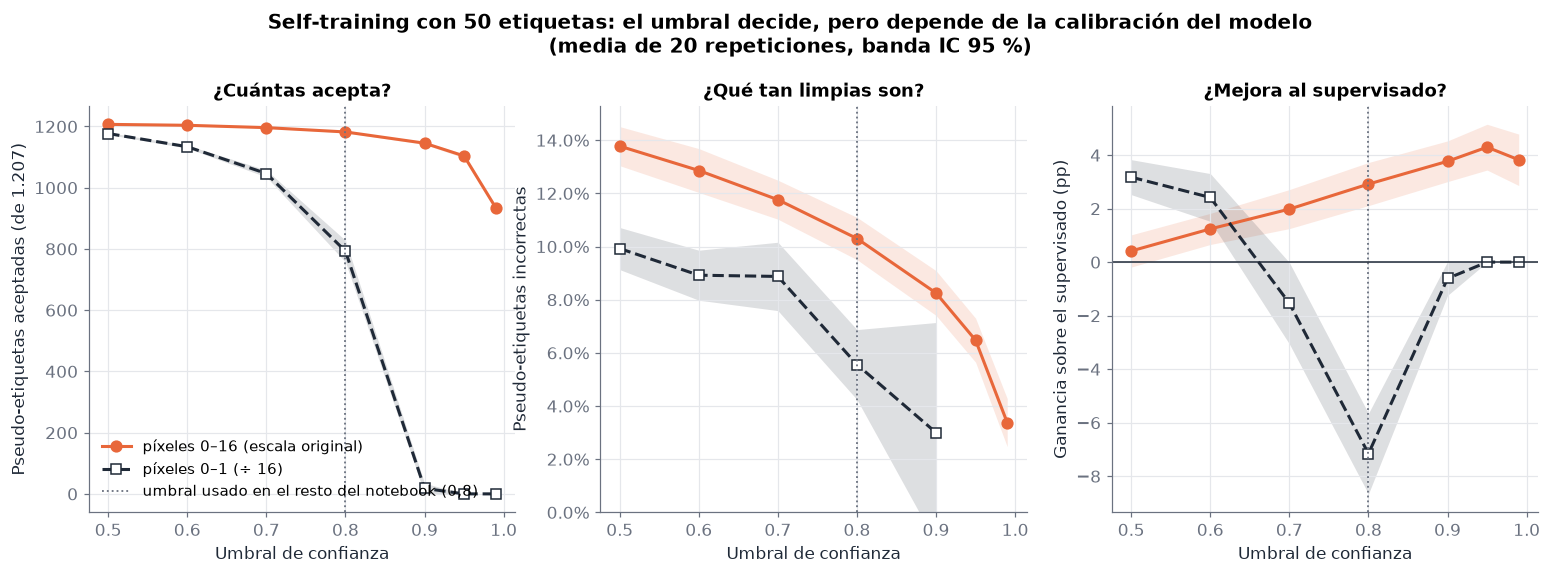

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
panel_specs = [
    ("pseudo_etiquetas", "Pseudo-etiquetas aceptadas (de 1.207)", "¿Cuántas acepta?"),
    ("error_pseudo", "Pseudo-etiquetas incorrectas", "¿Qué tan limpias son?"),
    ("ganancia_pp", "Ganancia sobre el supervisado (pp)", "¿Mejora al supervisado?"),
]
for ax, (column, ylabel, title) in zip(axes, panel_specs):
    for scale_name, style in SCALE_STYLES.items():
        values = threshold_results[threshold_results["escala"] == scale_name].groupby("umbral")[column]
        plot_mean_with_ci(ax, THRESHOLDS, values, scale_name,
                          mfc="white" if style["linestyle"] == "--" else None, **style)
    ax.axvline(CONFIDENCE_THRESHOLD, color=GRAY, linestyle=":", linewidth=1.2,
               label="umbral usado en el resto del notebook (0,8)")
    ax.set(xlabel="Umbral de confianza", ylabel=ylabel, title=title)
axes[1].yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
axes[1].set_ylim(bottom=0)
axes[2].axhline(0, color=INK, linewidth=1)
axes[0].legend(loc="lower left", fontsize=9.5)
fig.suptitle(f"Self-training con {MAIN_BUDGET} etiquetas: el umbral decide, pero depende de la calibración del modelo\n"
             f"(media de {N_REPETITIONS} repeticiones, banda IC 95 %)", y=1.06, fontsize=13, fontweight="bold")
save_figure(fig, "fig06_umbral_self_training")
plt.show()

**Escala original (0–16).** Se observa el compromiso esperado: al subir el umbral se aceptan menos pseudo-etiquetas (de 1.206 a 935) y con menos errores (del 13,8 % al 3,4 %), y la ganancia crece de +0,4 a +4,3 pp con umbral 0,95. Con 0,99 disminuye ligeramente porque se descartan demasiadas.

**Escala 0–1.** La misma regresión logística, con los mismos datos y las mismas etiquetas, produce probabilidades menos extremas. Con umbrales bajos (0,5–0,6) el self-training funciona (+3,2 pp con 0,5). Con 0,8 pierde 7,2 pp y empeora al modelo supervisado en las 20 repeticiones. Con 0,9 o más casi no acepta pseudo-etiquetas y el resultado coincide con el del supervisado.

Lo más llamativo es que, con umbral 0,8, las pseudo-etiquetas de la escala 0–1 tienen menos errores (5,6 %) que las de la escala original (10,3 %) y aun así el modelo empeora. La tasa de error de las pseudo-etiquetas no basta para explicar el daño; la sección 4.1 muestra qué falta.

**Implicación práctica.** El umbral no es un valor universal: 0,8 significa cosas distintas para modelos calibrados de forma distinta. Por eso conviene ajustarlo con validación y comparar siempre contra el modelo supervisado. El problema es que, con 50 etiquetas, quedan muy pocos datos para validar.

### 4.1 El sesgo de confirmación, clase por clase

Los promedios esconden *dónde* se equivoca el self-training. Con el umbral de 0,8 contamos cuántas pseudo-etiquetas recibió cada dígito (promedio de las 20 repeticiones) y comparamos el *recall* por clase en prueba —la fracción de imágenes de cada dígito que el modelo reconoce— antes y después del self-training.

Figura guardada en figures/fig07_sesgo_confirmacion_por_clase.png


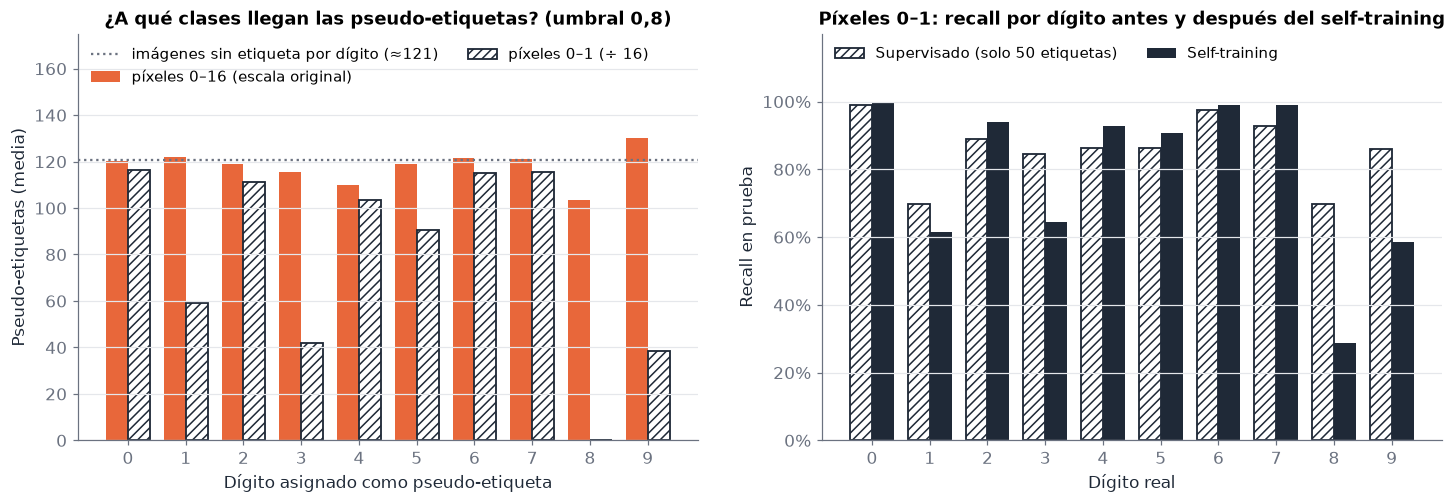

dígito,0,1,2,3,4,5,6,7,8,9
pseudo-etiquetas (0–16),120.25,121.95,118.75,115.65,110.10,118.90,121.40,121.20,103.45,130.10
pseudo-etiquetas (0–1),116.35,59.10,111.40,41.90,103.55,90.70,115.20,115.65,0.20,38.50
recall supervisado (0–1),0.99,0.70,0.89,0.84,0.86,0.86,0.97,0.93,0.70,0.86
recall self-training (0–1),1.00,0.62,0.94,0.64,0.93,0.91,0.99,0.99,0.29,0.59


In [20]:
at_threshold = threshold_results[threshold_results["umbral"] == CONFIDENCE_THRESHOLD]
unlabeled_per_class = (len(y_digits) * (1 - TEST_SIZE) - MAIN_BUDGET) / N_CLASSES   # ≈ 121 por dígito

fig, (ax_counts, ax_recall) = plt.subplots(1, 2, figsize=(16, 4.8))
width = 0.38
for offset, (scale_name, style) in zip([-width / 2, width / 2], SCALE_STYLES.items()):
    subset = at_threshold[at_threshold["escala"] == scale_name]
    counts = np.mean(np.stack(subset["pseudo_por_clase"]), axis=0)
    fill = dict(color=style["color"]) if style["linestyle"] == "-" else dict(facecolor="white", edgecolor=style["color"], hatch="////")
    ax_counts.bar(CLASSES + offset, counts, width=width, label=scale_name, linewidth=1.2, **fill)
ax_counts.axhline(unlabeled_per_class, color=GRAY, linestyle=":", linewidth=1.5,
                  label=f"imágenes sin etiqueta por dígito (≈{unlabeled_per_class:.0f})")
ax_counts.set(xticks=CLASSES, xlabel="Dígito asignado como pseudo-etiqueta", ylim=(0, 175),
              ylabel="Pseudo-etiquetas (media)", title=f"¿A qué clases llegan las pseudo-etiquetas? (umbral {CONFIDENCE_THRESHOLD})".replace(".", ","))
ax_counts.legend(loc="upper left", fontsize=9.5, ncol=2)
ax_counts.grid(axis="x", visible=False)

scaled = at_threshold[at_threshold["escala"] == "píxeles 0–1 (÷ 16)"]
recall_before = np.mean(np.stack(scaled["recall_supervisado"]), axis=0)
recall_after = np.mean(np.stack(scaled["recall_st"]), axis=0)
ax_recall.bar(CLASSES - width / 2, recall_before, width=width, facecolor="white", edgecolor=INK, hatch="////",
              linewidth=1.2, label="Supervisado (solo 50 etiquetas)")
ax_recall.bar(CLASSES + width / 2, recall_after, width=width, color=INK, label="Self-training")
ax_recall.set(xticks=CLASSES, xlabel="Dígito real", ylabel="Recall en prueba", ylim=(0, 1.2),
              yticks=np.linspace(0, 1, 6), title="Píxeles 0–1: recall por dígito antes y después del self-training")
ax_recall.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
ax_recall.legend(loc="upper left", fontsize=9.5, ncol=2)
ax_recall.grid(axis="x", visible=False)
save_figure(fig, "fig07_sesgo_confirmacion_por_clase")
plt.show()

original = at_threshold[at_threshold["escala"] == "píxeles 0–16 (escala original)"]
pd.DataFrame({
    "pseudo-etiquetas (0–16)": np.mean(np.stack(original["pseudo_por_clase"]), axis=0),
    "pseudo-etiquetas (0–1)": np.mean(np.stack(scaled["pseudo_por_clase"]), axis=0),
    "recall supervisado (0–1)": recall_before,
    "recall self-training (0–1)": recall_after,
}, index=pd.Index(CLASSES, name="dígito")).round(2).T

**Interpretación.** Con la escala original, las pseudo-etiquetas se reparten de forma casi uniforme (entre 103 y 130 por dígito, cerca de las aproximadamente 121 imágenes reales de cada uno). Con la escala 0–1 y umbral 0,8, el reparto se desequilibra: el dígito 8 recibe en promedio 0,2 pseudo-etiquetas, el 9 recibe 38,5, el 3 recibe 41,9 y el 1 recibe 59,1. Las clases en las que el modelo inicial tenía menos confianza casi nunca superan el umbral, mientras que las más fáciles (0, 6 y 7) reciben unas 115 cada una.

Al reentrenarse con un conjunto desbalanceado, el modelo "aprende" que el 8 es poco frecuente: su recall cae del 70 % al 29 %, el del 9 del 86 % al 59 % y el del 3 del 84 % al 64 %, mientras que los dígitos fáciles mejoran ligeramente. Es la forma más dañina del sesgo de confirmación: no hace falta aceptar muchas pseudo-etiquetas erróneas, basta con que el modelo refuerce solo lo que ya sabía. Es el mismo mecanismo que provocó el colapso en las dos lunas.

Este efecto está documentado en la literatura. Arazo et al. (2020) analizan el sesgo de confirmación en el pseudo-etiquetado y Wei et al. (2021) estudian el desbalance de clases que induce el self-training. También explica por qué métodos posteriores, como FlexMatch (Zhang et al., 2021), ajustan un umbral distinto para cada clase.

## 5. Conclusiones

### Respuesta a la pregunta

1. **Los datos sin etiqueta mejoran el clasificador de forma notable cuando las etiquetas escasean.** Con 50 etiquetas, label spreading alcanza el 94,1 % frente al 86,4 % de su contraparte supervisada (+7,7 pp, mejor en las 20 repeticiones) y queda a 2,1 puntos de una regresión logística entrenada con las 1.257 etiquetas.
2. **La mejora depende de que la estructura de los datos refleje las clases.** En las dos lunas, la ventaja de label spreading pasa de +18,6 pp a 0 cuando la concordancia de vecinos baja del 100 % al 73,5 %. Los dígitos, con un 97,3 % de concordancia, están en el régimen favorable, y eso explica por qué el método basado en grafos supera al self-training.
3. **La mejora se agota al aumentar las etiquetas.** La de label spreading pasa de +23,1 pp con 10 etiquetas a +0,5 pp, no significativa, con 200; la del self-training, de +8,0 a +0,8 pp.
4. **El self-training puede empeorar el modelo**, y el riesgo principal no es solo cuántas pseudo-etiquetas son erróneas, sino a qué clases se asignan. Con los píxeles en escala 0–1 y umbral 0,8, el modelo pierde 7,2 pp en las 20 repeticiones aunque solo el 5,6 % de sus pseudo-etiquetas son incorrectas. En las dos lunas, el mismo mecanismo lleva la exactitud al 50 %.

### Recomendaciones prácticas

- Antes de aplicar un método semisupervisado, comprobar si la estructura de los datos acompaña a las clases (por ejemplo, con la concordancia de vecinos sobre las observaciones etiquetadas).
- Comparar siempre contra un modelo supervisado de la misma familia, entrenado solo con las etiquetas disponibles.
- En self-training, revisar no solo la tasa de error de las pseudo-etiquetas, sino también su distribución por clase.
- Ajustar el umbral de confianza con validación, teniendo en cuenta que depende de la calibración del modelo base.

### Limitaciones

- **Un solo conjunto de datos real**, pequeño (imágenes de 8 × 8) y especialmente favorable al aprendizaje semisupervisado. En problemas con clases más solapadas, la parte 2 sugiere que la ganancia sería menor.
- **Hiperparámetros fijos y no validados** (7 vecinos, α = 0,99, umbral 0,8). Lo hicimos así para no ajustar nada con el conjunto de prueba, pero en la práctica habría que validarlos, y con 50 etiquetas eso es difícil.
- **Métodos clásicos.** No incluimos métodos de *consistency regularization* como FixMatch, que requieren redes profundas y aumentación de datos y no caben en un ejemplo reproducible en CPU en pocos minutos. Sus mecanismos de fondo, las pseudo-etiquetas con umbral y la suavidad local, son los que estudiamos aquí.
- **Misma distribución.** Los datos sin etiqueta provienen de la misma distribución que los etiquetados. No evaluamos el caso en que difieren, que según Oliver et al. (2018) puede perjudicar al modelo.
- **Etiquetas balanceadas.** En la práctica, una muestra aleatoria de pocas etiquetas puede dejar dígitos sin ningún ejemplo, y el desbalance resultante agravaría el problema descrito en la sección 4.1.

## Referencias

- Alpaydin, E. y Kaynak, C. (1998). *Optical Recognition of Handwritten Digits* [conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C50P49
- Arazo, E., Ortego, D., Albert, P., O'Connor, N. E. y McGuinness, K. (2020). Pseudo-labeling and confirmation bias in deep semi-supervised learning. *International Joint Conference on Neural Networks (IJCNN)*.
- Chapelle, O., Schölkopf, B. y Zien, A. (Eds.) (2006). *Semi-Supervised Learning*. MIT Press.
- Oliver, A., Odena, A., Raffel, C., Cubuk, E. D. y Goodfellow, I. (2018). Realistic evaluation of deep semi-supervised learning algorithms. *Advances in Neural Information Processing Systems 31*.
- Pedregosa, F. et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. Documentación del módulo `sklearn.semi_supervised`: https://scikit-learn.org/stable/modules/semi_supervised.html
- Sohn, K. et al. (2020). FixMatch: Simplifying semi-supervised learning with consistency and confidence. *Advances in Neural Information Processing Systems 33*.
- van Engelen, J. E. y Hoos, H. H. (2020). A survey on semi-supervised learning. *Machine Learning, 109*, 373–440. https://doi.org/10.1007/s10994-019-05855-6
- Wei, C., Sohn, K., Mellina, C., Yuille, A. y Yang, F. (2021). CReST: A class-rebalancing self-training framework for imbalanced semi-supervised learning. *IEEE/CVF Conference on Computer Vision and Pattern Recognition (CVPR)*.
- Yarowsky, D. (1995). Unsupervised word sense disambiguation rivaling supervised methods. *Proceedings of ACL*, 189–196. (Origen del self-training.)
- Zhang, B., Wang, Y., Hou, W., Wu, H., Wang, J., Okumura, M. y Shinozaki, T. (2021). FlexMatch: Boosting semi-supervised learning with curriculum pseudo labeling. *Advances in Neural Information Processing Systems 34*.
- Zhou, D., Bousquet, O., Lal, T. N., Weston, J. y Schölkopf, B. (2004). Learning with local and global consistency. *Advances in Neural Information Processing Systems 16*. (Label spreading.)
- Zhu, X. y Ghahramani, Z. (2002). *Learning from labeled and unlabeled data with label propagation*. Technical Report CMU-CALD-02-107, Carnegie Mellon University.